In [1]:
import numpy as np
from matplotlib import pyplot as plt
import json
from pastis.dataset_PASTIS import PASTIS_Dataset

In [7]:
dt = PASTIS_Dataset(
    folder="/home/hkerino/Documents/PASTIS", return_id=True, folds=[1, 2, 3, 4, 5]
)
print(f"length {dt.__len__()}")

Reading patch metadata . . .
Done.
Dataset ready.
length 2433


In [8]:
def count_label(dataset, plot=True):
    classes = np.zeros(20)

    for i in range(len(dataset)):
        labels = dataset[i][1].flatten().numpy()
        if np.any(labels < 0):
            print(f"Échantillon {i} : labels contiennent des valeurs négatives !")
            print(f"Valeurs uniques : {np.unique(labels)}")
            continue  # Exclure cet échantillon

        counts = np.bincount(labels, minlength=20)
        classes += counts

    normalized_count = classes / (np.sum(classes))
    name_labels = json.load(open("/home/hkerino/Documents/PASTIS/label_names.json"))
    if plot:
        plt.figure(figsize=(12, 6))
        plt.title("Normalized labels repartition")
        plt.bar(range(normalized_count.shape[0]), normalized_count)
        plt.xticks(range(len(normalized_count)), name_labels.values(), rotation=90)
        plt.ylabel("Labels occurence")

    return normalized_count

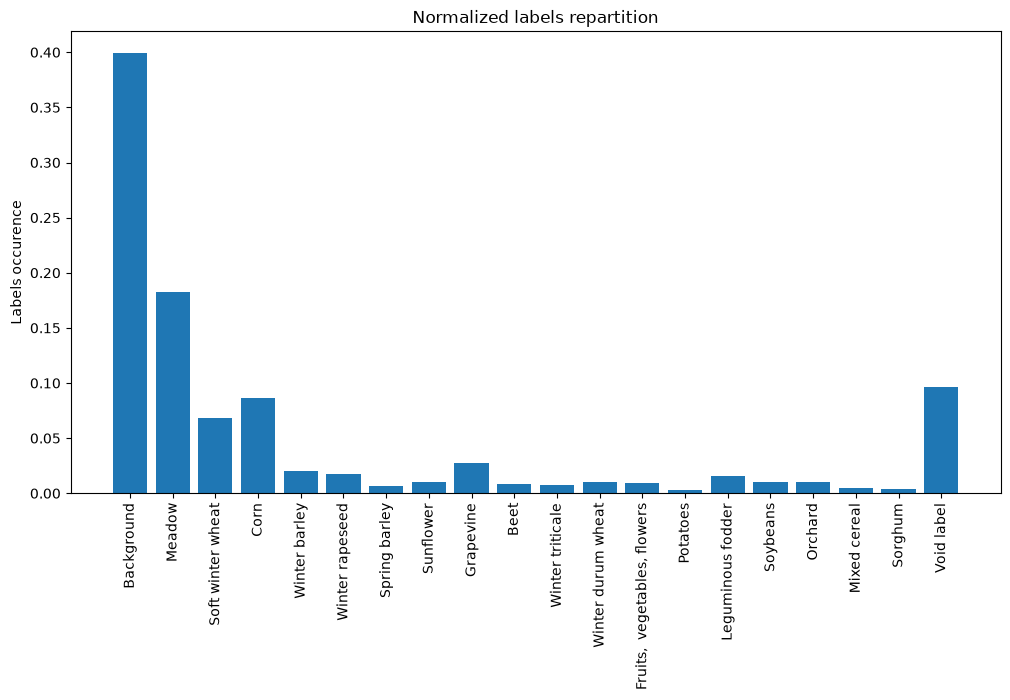

In [9]:
normalized_count = count_label(dt)